# Function 2 — Week 5: Neural Networks and Other Surrogates

**Retrospective discussion study, 29 October 2026.** Use the 14
official observations through the fourth returned round. The fifth query is
already submitted and its result is pending. This experiment supplies evidence
for the seven reflection criteria; it does not replace the submission or explain
an earlier decision using later analysis. No course function is evaluated.

Read the generated [study report](surrogate-study/report.md) after executing.

In [1]:
%matplotlib inline
from pathlib import Path
import hashlib
import json
import sys
import numpy as np
import pandas as pd
from IPython.display import display, Markdown

repository_dir = next(folder for folder in Path.cwd().parents if (folder / "run-python.ps1").is_file())
expected_python = repository_dir / ".venv" / ("Scripts/python.exe" if sys.platform == "win32" else "bin/python")
if Path(sys.executable).resolve() != expected_python.resolve():
    raise RuntimeError(f"Select the Capstone kernel: {expected_python}")
shared_dir = repository_dir / "stage-2-bbo/notebooks/Shared"
if str(shared_dir) not in sys.path:
    sys.path.insert(0, str(shared_dir))
from exploration_review_helpers import load_exploration_review
from surrogate_study_helpers import (
    make_study_models, evaluate_regressors, evaluate_classifiers,
    summarise_network_seeds, interpret_study,
)
from surrogate_study_plots import (
    validation_overview, seed_stability, classifier_confusions,
    gradient_comparison, conditional_boundaries, support_profiles, gradient_paths,
)
from surrogate_study_report import json_safe, write_study_report
print(f"Python interpreter: {sys.executable}")

Python interpreter: C:\_Source\Imperial-ML-AI-Live\Capstone\imperial-capstone\.venv\Scripts\python.exe


In [2]:
# Declare the complete, bounded experiment before fitting.
FUNCTION_NUMBER = 2
STUDY_DATE = "2026-10-29"
INPUT_COLUMNS = ['x1', 'x2']
EXPECTED_ROUND_COUNTS = {0: 10, 1: 1, 2: 1, 3: 1, 4: 1}
ANALYSIS_DIR = Path.cwd().resolve()
DATA_PATH = ANALYSIS_DIR / "observations.csv"
STUDY_DIR = ANALYSIS_DIR / "surrogate-study"
SUBMITTED_PATH = repository_dir / "stage-2-bbo/submissions/Week_05/submissions.txt"
ARCHITECTURES = [
    {"name": "tanh-8", "layers": [8], "activation": "tanh"},
    {"name": "tanh-16", "layers": [16], "activation": "tanh"},
    {"name": "relu-8-8", "layers": [8, 8], "activation": "relu"},
]
SEEDS = [11, 42, 73]
REPRESENTATIVE_SEED = 42
MODEL_SETTINGS = dict(alpha=0.1, max_iter=400, max_fun=15000, tolerance=1e-6, gp_restarts=3)
GP_FEATURE_SETS = {"GP x1 only": [0]} if FUNCTION_NUMBER == 2 else None
GOOD_QUANTILE = 0.75
HEIGHT_SCALE = 1e-200  # Function 1's existing fixed signed-log scale, not an estimated noise level.
CANDIDATE_SETTINGS = dict(broad_power=12, local_power=10, local_radius=0.15)
GRADIENT_SETTINGS = dict(gradient_step=1e-5, path_steps=8, path_step_size=0.05)
BOUNDARY_GRID_SIDE = 100
TITLE = f"Function {FUNCTION_NUMBER} — Week 5 surrogate study"

## Evidence, objective and validation design

Keep every official observation and every original coordinate. Regression
predicts the numerical score; classification separately asks whether a new
result reaches the training history's upper quartile. Thresholds, input scaling
and regression target scaling are fitted inside each held-out training fold.
The models see identical held-out rows. The small adaptive sample and reuse of
validation scores for architecture comparison limit any claim of generalisation.

Function 1 retains its fixed, monotone signed-log score transform. Its metrics
and regression gradients use those transformed units, preserving sign and
ordering rather than maximising absolute magnitude. Other functions use raw
signed-score units. Higher remains better for all eight functions.

In [3]:
review = load_exploration_review(DATA_PATH, input_columns=INPUT_COLUMNS,
    expected_round_counts=EXPECTED_ROUND_COUNTS)
data = review["plot_data"].drop(columns="rank")
inputs = review["inputs"].to_numpy(dtype=float)
raw_y = review["outputs"].to_numpy(dtype=float)
if FUNCTION_NUMBER == 1:
    function_shared = shared_dir.parent / "Function_1/FunctionSpecificShared"
    if str(function_shared) not in sys.path:
        sys.path.insert(0, str(function_shared))
    from function_1_model_helpers import signed_log
    target = signed_log(raw_y, scale=HEIGHT_SCALE)
    target_units = "signed-log score"
else:
    target, target_units = raw_y.copy(), "score"
assert np.isfinite(target).all() and np.argmax(target) == np.argmax(raw_y)
source_hash = hashlib.sha256(DATA_PATH.read_bytes()).hexdigest()
submitted_hash = hashlib.sha256(SUBMITTED_PATH.read_bytes()).hexdigest()
submitted_portal = SUBMITTED_PATH.read_text(encoding="utf-8").splitlines()[FUNCTION_NUMBER-1]
submitted_point = np.array([float(value) for value in submitted_portal.split("-")])
assert len(submitted_point) == len(INPUT_COLUMNS)
STUDY_DIR.mkdir(exist_ok=True)
display(pd.Series({"Official observations": len(target), "Input dimensions": inputs.shape[1],
    "Target units": target_units, "Confirmed feedback through round": 4,
    "Submitted Week 5 input": submitted_portal, "Future queries remaining": 8}))

Official observations                              14
Input dimensions                                    2
Target units                                    score
Confirmed feedback through round                    4
Submitted Week 5 input              0.636151-0.495605
Future queries remaining                            8
dtype: object

## Regression: simpler models, kernel methods and nine neural fits

The networks use L-BFGS with backpropagated parameter gradients, a fixed
regularisation strength and a fixed iteration cap. There is no adaptive
hyperparameter search. Fit warnings are retained. Architecture summaries average
all three initialisations; seed 42 is the declared representative. GP covariance
is fitted under its existing bounds. Neither training fit nor a lucky seed is
accepted as independent validation evidence.

In [4]:
regressors, classifiers, network_metadata = make_study_models(len(INPUT_COLUMNS),
    architectures=ARCHITECTURES, seeds=SEEDS, gp_feature_sets=GP_FEATURE_SETS, **MODEL_SETTINGS)
regression = evaluate_regressors(regressors, inputs, target)
reg_networks = summarise_network_seeds(regression, network_metadata,
    task="regression", representative_seed=REPRESENTATIVE_SEED)
display(regression["table"].round(6))
display(reg_networks["table"].round(6))

Regression complete: Mean baseline; warnings=0


Regression complete: Linear regression; warnings=0


Regression complete: Ridge; warnings=0


Regression complete: Kernel ridge; warnings=0


Regression complete: RBF SVR; warnings=0


...

Regression complete: NN relu-8-8 seed 11; warnings=0


Regression complete: NN relu-8-8 seed 42; warnings=1


Regression complete: NN relu-8-8 seed 73; warnings=1


,Model,LOO RMSE,LOO MAE,Rank correlation,Training RMSE,Fit warnings,RMSE / baseline
0,GP x1 only,0.145783,0.119795,0.578022,0.007838,12,0.677690
1,GP separate length scales,0.147264,0.120021,0.683516,0.004941,0,0.684575
2,Ridge,0.183802,0.141243,0.564835,0.146029,0,0.854424
3,Linear regression,0.187074,0.144931,0.520879,0.145807,0,0.869636
4,RBF SVR,0.189330,0.152190,0.468132,0.144260,0,0.880122
5,Mean baseline,0.215118,0.177465,-1.000000,0.199752,0,1.000000
6,GP shared length scale,0.223697,0.185444,-0.301099,0.002103,0,1.039881
7,NN relu-8-8 seed 11,0.227031,0.163720,0.481319,0.051437,0,1.055381
8,Kernel ridge,0.239979,0.199755,0.367033,0.100028,0,1.115571
9,NN relu-8-8 seed 73,0.253365,0.193868,0.419780,0.084880,1,1.177799


,architecture,mean,std,min,max
0,relu-8-8,0.248310,0.019256,0.227031,0.264534
1,tanh-8,0.260443,0.000678,0.259669,0.260935
2,tanh-16,0.261076,0.002728,0.257979,0.263124


## Classification: a training-relative good/bad boundary

A held-out result is labelled good only if it reaches the threshold computed
from the remaining training results. This avoids using its outcome to set its
own threshold. The final fitted boundary uses the full-data threshold and is
therefore a different, explicitly labelled view. No true boundary is known.

Compare balanced accuracy, good-result recall, false negatives/positives and
probability scores where available. SVM decision scores support ROC AUC but
are not probabilities; Brier score and log loss are left unavailable for SVMs.
Classification loses score magnitudes and remains a secondary framing of the
original maximisation problem.

In [5]:
classification = evaluate_classifiers(classifiers, inputs, target, quantile=GOOD_QUANTILE)
class_networks = summarise_network_seeds(classification, network_metadata,
    task="classification", representative_seed=REPRESENTATIVE_SEED)
display(classification["table"].round(6))
display(class_networks["table"].round(6))
display(pd.Series({"Full-data threshold in target units": classification["threshold"],
    "Full-data good labels": int(classification["labels"].sum()),
    "Held-out good labels under fold thresholds": int(classification["truth"].sum()),
    "Smallest training-fold threshold": classification["fold_thresholds"].min(),
    "Largest training-fold threshold": classification["fold_thresholds"].max(),
    "Fold labels differing from full-data labels": int((classification["truth"] != classification["labels"]).sum())}))

Classification complete: Class-prior baseline; warnings=0


Classification complete: Logistic regression; warnings=0


Classification complete: Linear SVM; warnings=0


Classification complete: RBF SVM; warnings=0


Classification complete: NN tanh-8 seed 11; warnings=0


...

Classification complete: NN relu-8-8 seed 42; warnings=3


Classification complete: NN relu-8-8 seed 73; warnings=0


,Model,LOO balanced accuracy,LOO accuracy,Good precision,Good recall,Good F1,ROC AUC,Brier score,Log loss,Training balanced accuracy,False negatives,False positives,Fit warnings
0,Logistic regression,0.775,0.785714,0.6,0.75,0.666667,0.775,0.165499,0.502808,0.650,1,2,0
1,Linear SVM,0.775,0.785714,0.6,0.75,0.666667,0.675,NaN,NaN,0.775,1,2,0
2,RBF SVM,0.775,0.785714,0.6,0.75,0.666667,0.675,NaN,NaN,0.700,1,2,0
3,NN relu-8-8 seed 11,0.775,0.785714,0.6,0.75,0.666667,0.650,0.232719,1.802544,0.900,1,2,0
4,NN relu-8-8 seed 42,0.775,0.785714,0.6,0.75,0.666667,0.675,0.220253,2.249615,1.000,1,2,3
5,NN relu-8-8 seed 73,0.775,0.785714,0.6,0.75,0.666667,0.625,0.217136,1.756632,0.900,1,2,0
6,NN tanh-8 seed 11,0.725,0.714286,0.5,0.75,0.600000,0.600,0.234302,1.160518,0.825,1,3,0
7,NN tanh-8 seed 42,0.725,0.714286,0.5,0.75,0.600000,0.600,0.234044,1.159407,1.000,1,3,0
8,NN tanh-8 seed 73,0.725,0.714286,0.5,0.75,0.600000,0.600,0.233872,1.143338,1.000,1,3,0
9,NN tanh-16 seed 11,0.725,0.714286,0.5,0.75,0.600000,0.600,0.235022,1.257588,1.000,1,3,0


,architecture,mean,std,min,max
0,relu-8-8,0.775,0.0,0.775,0.775
1,tanh-16,0.725,0.0,0.725,0.725
2,tanh-8,0.725,0.0,0.725,0.725


Full-data threshold in target units            0.291356
Full-data good labels                          4.000000
Held-out good labels under fold thresholds     4.000000
Smallest training-fold threshold               0.283444
Largest training-fold threshold                0.293993
Fold labels differing from full-data labels    0.000000
dtype: float64

## Actual support vectors and checked input backpropagation

The fitted linear and RBF SVMs now identify actual support vectors. Their
decision scores indicate position relative to the fitted boundary, rather than
Euclidean input-space distance. Keep all coordinates and observation IDs visible.

Input backpropagation differentiates the fixed trained network's score or
P(good). This differs from the parameter gradients used to train its weights.
Independent finite differences check both representative networks at three
declared interior points. Sensitivities are local or sampled, model-dependent
and non-causal. Small gradients can reflect saturation rather than irrelevance.

In [6]:
interpretation = interpret_study(regression, classification, reg_networks, class_networks,
    inputs, target, data, submitted_point, input_columns=INPUT_COLUMNS,
    candidate_settings=CANDIDATE_SETTINGS, **GRADIENT_SETTINGS)
display(interpretation["parameter_counts"])
display(interpretation["gradient_checks"])
display(interpretation["gradient_table"].round(6))
print(f"RBF SVM support vectors: {interpretation['support_count']} / {len(target)}")
display(interpretation["support"][["observation_id", *INPUT_COLUMNS, "y", "Good class", "Decision score"]])
print(f"Linear SVM support vectors: {interpretation['linear_support_count']} / {len(target)}")
display(interpretation["linear_support"][["observation_id", *INPUT_COLUMNS, "y", "Good class", "Decision score"]])

,Model,Trainable parameters,Observations,Final iterations
0,NN relu-8-8 seed 11,105,14,86
1,NN relu-8-8 seed 42,105,14,168
2,NN relu-8-8 seed 73,105,14,127


,Model,Maximum absolute error,Maximum normalised error,Passed
0,NN relu-8-8 seed 42,1.180123e-11,3.300975e-12,True
1,NN relu-8-8 seed 42,5.768889e-08,1.921808e-08,True


,Input,NN backpropagation,GP finite difference,SVR finite difference,NN sampled mean absolute gradient,NN seed SD of mean absolute gradient,NN P(good) gradient near boundary
0,x1,0.007444,-3.024403,0.232845,0.859624,0.065934,8.144645
1,x2,0.002954,0.000000,-0.148340,0.547818,0.260604,0.667255


RBF SVM support vectors: 10 / 14


,observation_id,x1,x2,y,Good class,Decision score
0,initial-010,0.702637,0.926564,0.611205,1,-0.023525
1,round-01,0.774999,0.949999,0.283444,0,0.209264
2,round-03,0.835565,0.232911,0.156096,0,-0.545416
3,initial-004,0.845275,0.711120,0.293993,1,0.551442
4,initial-006,0.577713,0.771973,0.023106,0,-0.566824
5,initial-001,0.665800,0.123969,0.538996,1,-0.603214
6,initial-002,0.877791,0.778628,0.420586,1,0.636879
7,initial-005,0.454647,0.290455,0.214965,0,-0.999669


Linear SVM support vectors: 9 / 14


,observation_id,x1,x2,y,Good class,Decision score
0,initial-001,0.665800,0.123969,0.538996,1,-0.079326
1,initial-010,0.702637,0.926564,0.611205,1,0.238122
2,initial-006,0.577713,0.771973,0.023106,0,-0.354333
3,round-01,0.774999,0.949999,0.283444,0,0.568836
4,round-03,0.835565,0.232911,0.156096,0,0.706720
5,initial-004,0.845275,0.711120,0.293993,1,0.840681
6,initial-007,0.438166,0.685018,0.244619,0,-0.999971
7,initial-002,0.877791,0.778628,0.420586,1,1.000029


## Compare predictions, stability, boundaries and sensitivities

Each plot is saved separately and embedded here. Higher-dimensional boundary
views vary the two inputs with the largest absolute neural probability
gradients near its sampled boundary, holding every other input fixed. Only
observations actually lying on that slice are overlaid. A 2D slice cannot
establish the full high-dimensional boundary. Neural seed variation is not
calibrated posterior uncertainty.

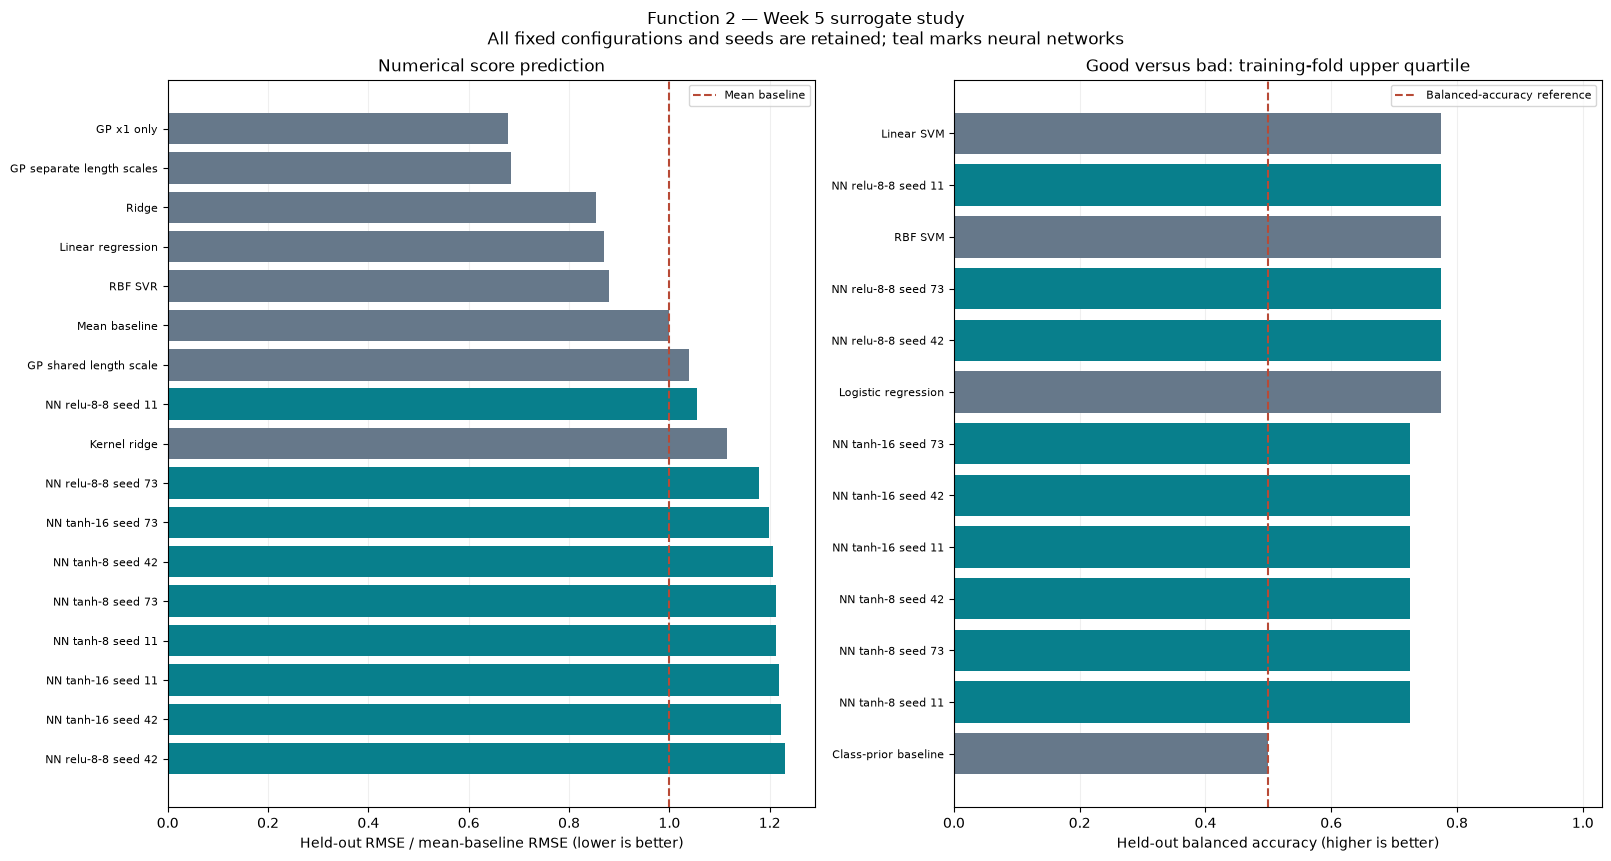

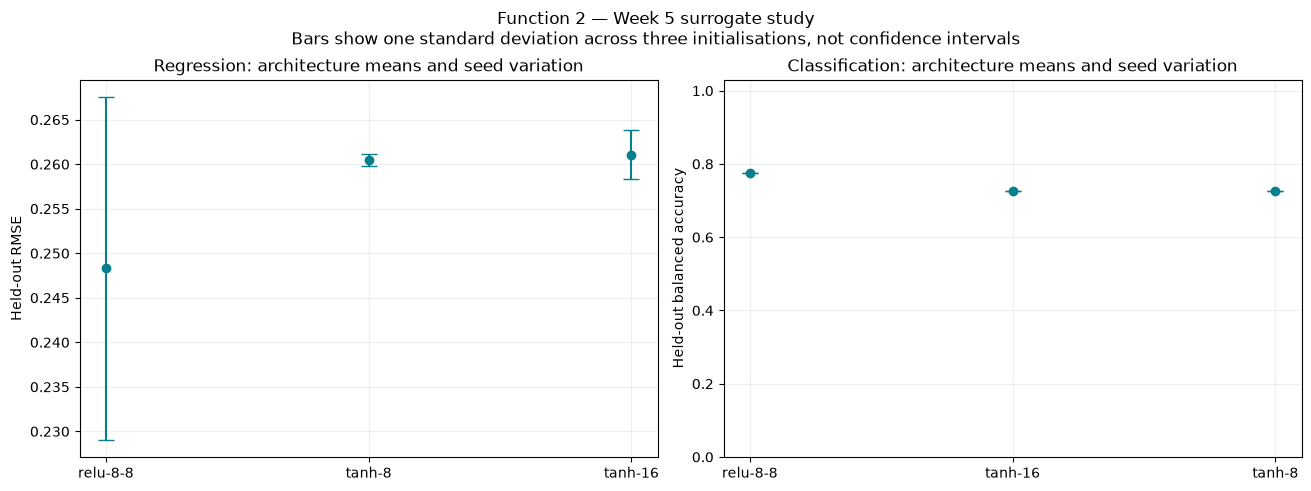

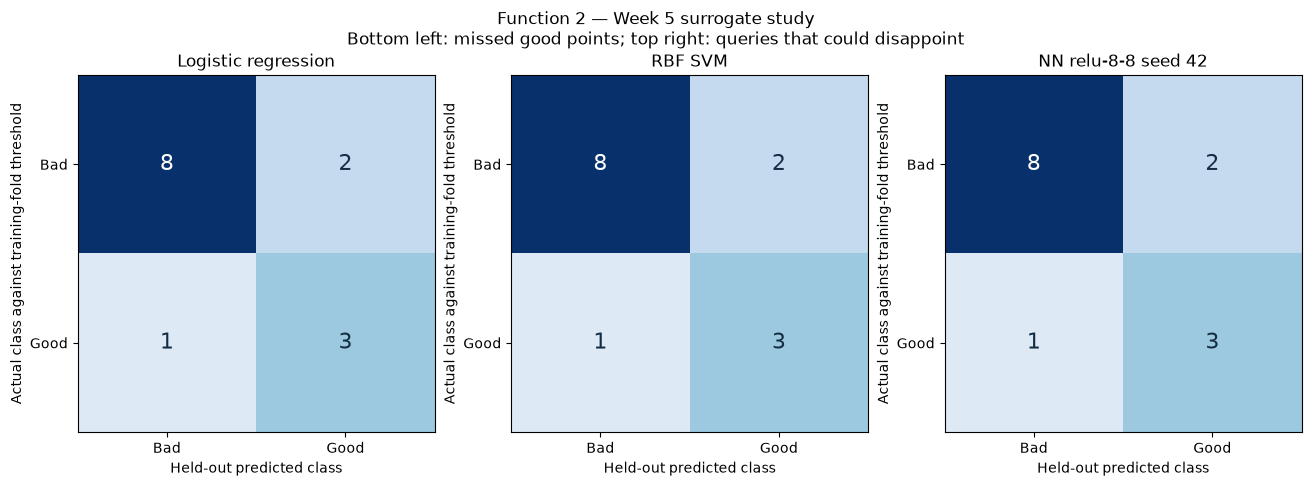

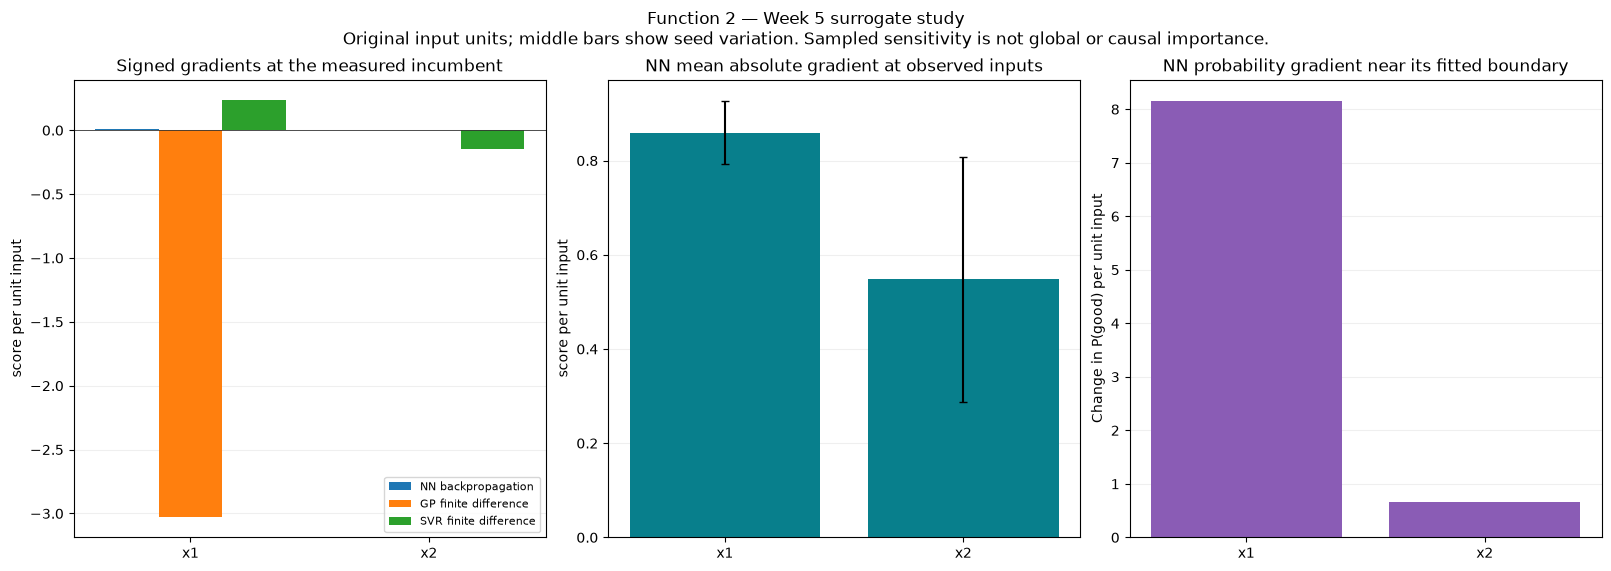

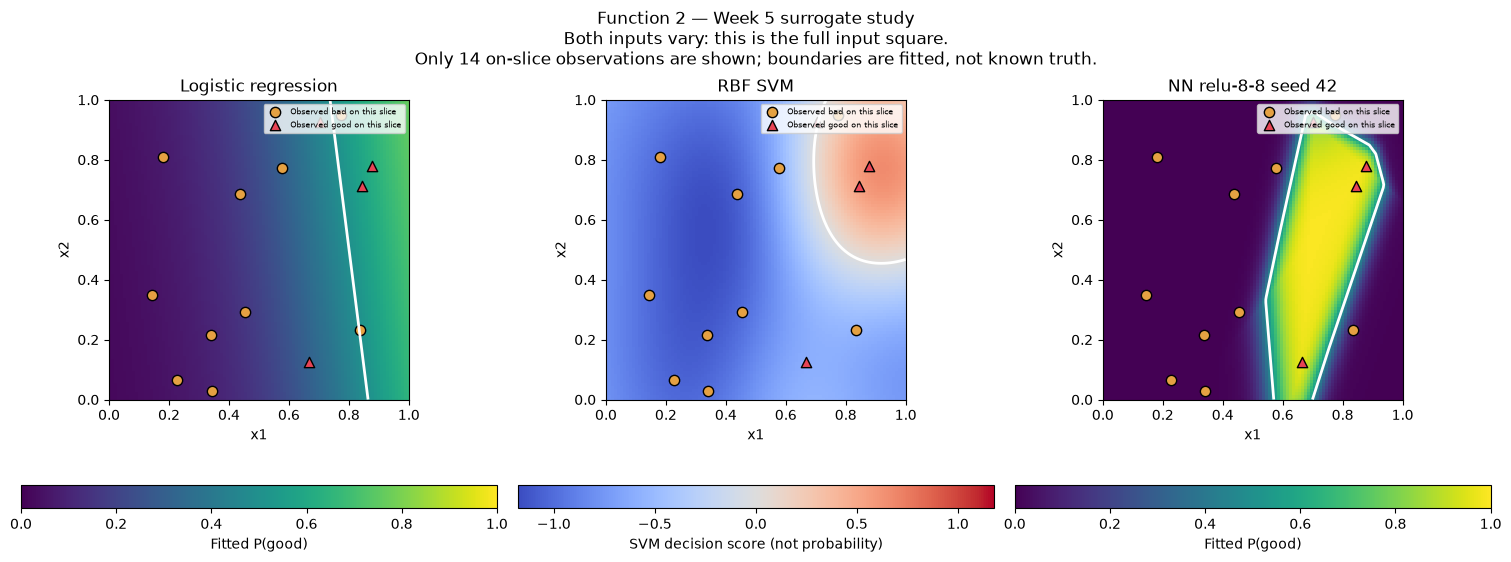

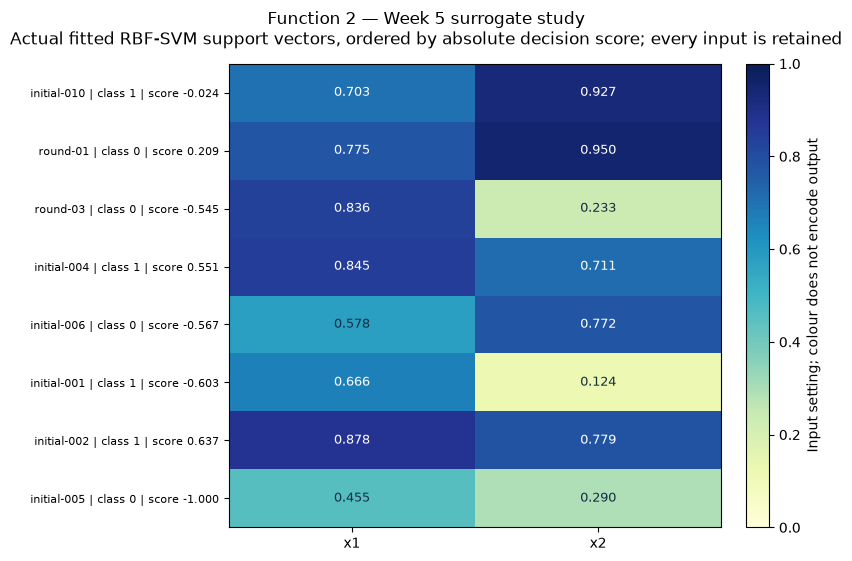

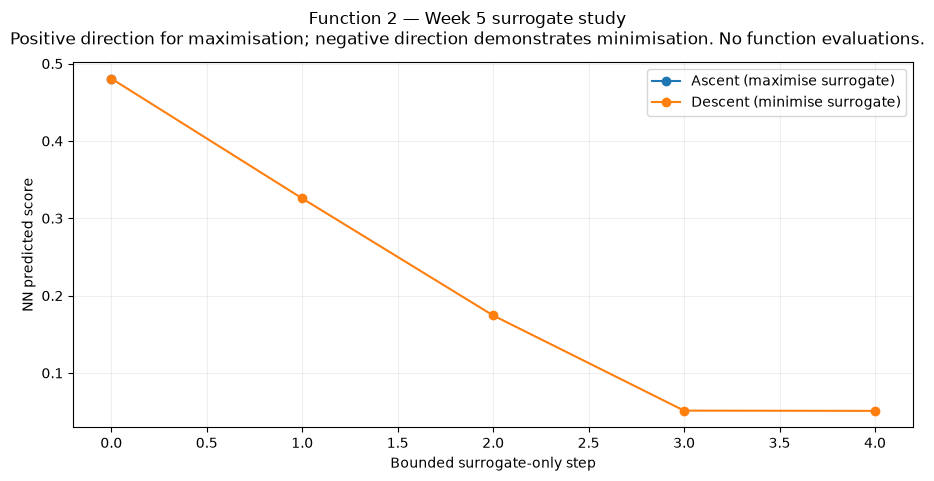

In [7]:
display(validation_overview(regression, classification, title=TITLE,
    save_to=STUDY_DIR / "validation-overview.png"))
display(seed_stability(reg_networks, class_networks, title=TITLE,
    save_to=STUDY_DIR / "seed-stability.png"))
display(classifier_confusions(classification,
    ["Logistic regression", "RBF SVM", class_networks["representative"]],
    title=TITLE, save_to=STUDY_DIR / "classification-confusions.png"))
display(gradient_comparison(INPUT_COLUMNS, interpretation["local_gradients"],
    interpretation["seed_gradient_mean"], interpretation["seed_gradient_sd"],
    interpretation["boundary_gradient"], title=TITLE, target_label=target_units,
    save_to=STUDY_DIR / "input-gradients.png"))
boundary_models = {name: classification["fitted"][name]
    for name in ["Logistic regression", "RBF SVM", class_networks["representative"]]}
display(conditional_boundaries(boundary_models, inputs, classification["labels"],
    interpretation["boundary_point"], interpretation["boundary_axes"], title=TITLE,
    side=BOUNDARY_GRID_SIDE, save_to=STUDY_DIR / "classification-boundaries.png"))
display(support_profiles(interpretation["support"], INPUT_COLUMNS, title=TITLE,
    save_to=STUDY_DIR / "support-vector-profiles.png"))
display(gradient_paths(interpretation["paths"], title=TITLE, target_label=target_units,
    save_to=STUDY_DIR / "gradient-paths.png"))

## Hypothetical queries and ascent/descent

Compare mean-only recommendations on one frozen candidate pool. All input
coordinates remain free, and candidates already measured at six decimals
are excluded. The three-seed ensemble's spread describes sensitivity to
initialisation; it is not a GP posterior SD. These recommendations neither
replace the submitted input nor predict a known improvement.

Bounded ascent follows the positive input gradient for maximisation. Descent
shows what reducing the fitted output would mean. Both use a short declared
step budget and require a predicted improvement in the requested direction.
They evaluate only the surrogate and provide no new black-box feedback.

In [8]:
display(interpretation["candidate_review"])
display(interpretation["submitted_predictions"])
print(f"Common unobserved candidates: {interpretation['candidate_count']}")
print("NN seed spread at its ensemble-mean winner:", interpretation["nn_ensemble_seed_spread_at_mean_winner"])
for direction, path in interpretation["paths"].items():
    print(direction)
    display(path)

,Method,Predicted score,Input,Nearest measured input
0,Linear regression: mean only,0.485096,0.999999-0.999999,0.230489
1,RBF SVR: mean only,0.321662,0.852625-0.828239,0.055629
2,GP x1 only: mean only,0.625282,0.691738-0.886631,0.041394
3,NN relu-8-8 seed 42: mean only,0.524470,0.665511-0.181993,0.058025
4,NN seed ensemble: mean only,0.517870,0.725547-0.001013,0.136704


,Model,Prediction at submitted input
0,Linear regression,0.259445
1,RBF SVR,0.267322
2,GP x1 only,0.321767
3,NN relu-8-8 seed 42,0.338647


Common unobserved candidates: 5128
NN seed spread at its ensemble-mean winner: 0.11368267038949274
Ascent (maximise surrogate)


,step,prediction,x1,x2
0,0,0.480719,0.702637,0.926564


Descent (minimise surrogate)


,step,prediction,x1,x2
0,0,0.480719,0.702637,0.926564
1,1,0.325692,0.656161,0.908124
2,2,0.174359,0.606201,0.906129
3,3,0.051292,0.556543,0.900293
4,4,0.050955,0.534772,0.888004


In [9]:
# Preserve numerical evidence and generate the seven reflection sections from it.
summary = json_safe({
    "function": FUNCTION_NUMBER, "week": 5, "study_date": STUDY_DATE,
    "analysis": "retrospective_neural_and_surrogate_comparison",
    "data_scope": "official_only", "feedback_through_round": 4,
    "observations": len(target), "dimensions": len(INPUT_COLUMNS), "target_units": target_units,
    "source_csv": str(DATA_PATH.relative_to(repository_dir)), "source_csv_sha256": source_hash,
    "submitted_input": submitted_portal, "submitted_file_sha256": submitted_hash,
    "settings": {"architectures": ARCHITECTURES, "seeds": SEEDS, "representative_seed": REPRESENTATIVE_SEED,
        "models": MODEL_SETTINGS, "good_quantile": GOOD_QUANTILE, "height_scale": HEIGHT_SCALE if FUNCTION_NUMBER == 1 else None,
        "candidates": CANDIDATE_SETTINGS, "gradients": GRADIENT_SETTINGS},
    "regression_comparison": regression["table"].to_dict(orient="records"),
    "classification_comparison": classification["table"].to_dict(orient="records"),
    "regression_seed_comparison": reg_networks["table"].to_dict(orient="records"),
    "classification_seed_comparison": class_networks["table"].to_dict(orient="records"),
    "selected_regression_architecture": reg_networks["architecture"],
    "selected_classification_architecture": class_networks["architecture"],
    "regression_representative": reg_networks["representative"],
    "classification_representative": class_networks["representative"],
    "reference_gp": interpretation["gp_name"],
    "classification_threshold": classification["threshold"],
    "full_good_count": int(classification["labels"].sum()),
    "held_out_good_count": int(classification["truth"].sum()),
    "training_fold_threshold_range": [classification["fold_thresholds"].min(), classification["fold_thresholds"].max()],
    "fold_labels_differing_from_full_labels": int((classification["truth"] != classification["labels"]).sum()),
    "rbf_support_count": interpretation["support_count"],
    "linear_support_count": interpretation["linear_support_count"],
    "rbf_support_examples": interpretation["support"][["observation_id", "Good class", "Decision score"]].to_dict(orient="records"),
    "input_gradients": interpretation["gradient_table"].to_dict(orient="records"),
    "gradient_checks": interpretation["gradient_checks"].to_dict(orient="records"),
    "conditional_boundary_axes": [INPUT_COLUMNS[i] for i in interpretation["boundary_axes"]],
    "conditional_boundary_anchor": interpretation["boundary_point"],
    "anchor_predicted_good_probability": interpretation["boundary_probability"],
    "candidate_count": interpretation["candidate_count"],
    "hypothetical_mean_only_candidates": interpretation["candidate_review"].to_dict(orient="records"),
    "nn_ensemble_seed_spread_at_mean_winner": interpretation["nn_ensemble_seed_spread_at_mean_winner"],
    "gradient_paths": {name: path.to_dict(orient="records") for name, path in interpretation["paths"].items()},
    "neural_parameter_counts": interpretation["parameter_counts"].to_dict(orient="records"),
    "fit_warnings": {"regression": regression["warnings"], "classification": classification["warnings"]},
    "estimator_fits": (len(regressors)+len(classifiers))*(len(target)+1),
    "submitted_inputs_changed": False, "new_course_evaluations": 0,
})
assert hashlib.sha256(DATA_PATH.read_bytes()).hexdigest() == source_hash
assert hashlib.sha256(SUBMITTED_PATH.read_bytes()).hexdigest() == submitted_hash
(STUDY_DIR / "results.json").write_text(json.dumps(summary, indent=2, allow_nan=False) + "\n", encoding="utf-8")
evidence = write_study_report(summary, STUDY_DIR)
display(Markdown("\n".join(line for line in evidence.splitlines() if not line.startswith("!["))))
print("Saved study evidence; source observations and submitted inputs are unchanged.")

## Evidence for the seven reflection points

### 1. Inputs acting as support vectors

The full-fit RBF SVM identifies **10 of 14**
observations as actual support vectors. Examples nearest its decision boundary
in absolute decision score are initial-010 (class 1, decision score -0.024), round-01 (class 0, decision score 0.209), round-03 (class 0, decision score -0.545). The linear SVM uses
**9** support vectors. Their full input profiles
are retained in the notebook table and figure. Kernel decision scores are not
Euclidean distances from the boundary. These points support the fitted classifier,
not a known true boundary of the hidden function. Nearby uncertain classifications
can motivate further exploration, while a large support-vector fraction warns
against assuming that a small set of boundary points has resolved the problem.


### 2. Surrogate gradients and directions

The study trains neural regressors and backpropagates their output derivatives
to the original input coordinates, including both fitted scalers. Independent
finite-difference checks pass for the representative regressor and classifier.
The bounded ascent demonstration accepts **0 steps**, changing the
NN prediction from **0.480719 to 0.480719**;
descent accepts **4 steps**, changing it from
**0.480719 to 0.0509555**. Zero accepted
steps mean no improving step was found under the declared step limits.
The project maximises its signed score, so ascent is the relevant query direction;
descent is included to address the assignment's minimisation wording. All these
predictions use **score**, and no new course evaluations occur.


### 3. Classification framing and exploration trade-offs

"Good" means a result at least as high as the training history's 75th percentile.
Every validation fold estimates its threshold from training outcomes only.
The final full-data threshold is **0.291356** in
score, giving **4 good** and
**10 bad** labels. Fold thresholds
vary; held-out metrics evaluate this training-relative rule rather than one fixed
oracle boundary. The representative NN misses **1** good
held-out results and falsely labels **2** bad results as
good. False negatives risk excluding promising regions; false positives spend
scarce queries. Labels discard output magnitude, so this is supporting evidence
alongside numerical maximisation, not a replacement objective.


### 4. Choice of model and interpretability

The representative NN's LOO RMSE is **0.264534**, compared with
**0.187074** for linear regression and **0.145783** for
the reference GP (**GP x1 only**). Averaging all three seeds of
the selected NN architecture gives RMSE **0.24831** with seed SD
**0.019256**. The architecture is selected by this mean, and seed 42
is the fixed representative rather than the luckiest seed. The average network
does not improve on the reference GP on these
observed validation targets. Linear coefficients are easier to explain; neural
curves and input gradients provide local interpretation. GP posterior uncertainty
and variation across neural initialisations answer different questions.


### 5. Input influence and priorities for exploration

The largest NN mean absolute gradients across the observed input locations are
**x1 (0.8596), x2 (0.5478)**, in score per unit input. These sampled
sensitivities average the selected architecture's three fitted seeds; they are
neither causal effects nor global importance. The separate signed gradients at
the incumbent and probability gradients near a fitted classification boundary
retain all inputs and can suggest different priorities. Every coordinate shares
the original 0–1 range. Larger, seed-stable gradients can motivate controlled
local perturbations, while small or unstable gradients still warrant coverage
checks rather than permanent exclusion of an input.


### 6. Neural decision boundary and backpropagation

The representative neural classifier has held-out balanced accuracy
**0.775**, good-result recall **0.750**
and Brier score **0.220**. Its full-fit training balanced
accuracy is **1.000**, so the training versus
held-out gap remains visible. Logistic regression scores
**0.775** and the RBF SVM
**0.775** on the same folds.
Backpropagation supplies weight gradients to the L-BFGS training optimiser;
the later input backpropagation differentiates the fixed trained model's
P(good). The latter is checked against finite differences and used to select
two informative plotting axes. Other coordinates remain fixed in higher-dimensional
slices, and observations away from that slice are omitted. These plots visualise
an estimated boundary, not measured truth throughout the domain. Softmax or
sigmoid confidence is not automatically calibrated uncertainty about unsampled regions.


### 7. Added neural flexibility versus simpler models

For regression, the selected architecture's mean RMSE is **0.24831**,
with individual seeds spanning **0.227031–0.264534**. The
representative fit has training RMSE **0.0628091**, compared
with held-out RMSE **0.264534**. For classification, its selected
architecture averages balanced accuracy **0.775** with seed SD
**0.000**, which does not exceed
the logistic baseline's **0.775**. Regression and
classification can therefore give different answers about the value of flexibility.
The bounded study retains **34 fitting warnings**, including iteration
limits where present, rather than increasing the budget until a network wins.
There are only 14 observations for 2
inputs. All configuration selection reuses these small validation samples, so
the comparison is exploratory and supplies no independent final-test guarantee.
The submitted Week 5 inputs remain unchanged; useful future decisions require
new returned evidence rather than lower training error alone.


Saved study evidence; source observations and submitted inputs are unchanged.
